In [1]:
import os
import random
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

from sklearn.model_selection import train_test_split
from sklearn import metrics

import tensorflow as tf
from tensorflow import keras
from keras import layers

import warnings
warnings.filterwarnings('ignore')

In [12]:
from zipfile import ZipFile

data_path = 'lung_subset_small.zip'
with ZipFile(data_path, 'r') as zip:
    zip.extractall()
    print('The data set has been extracted.')

The data set has been extracted.


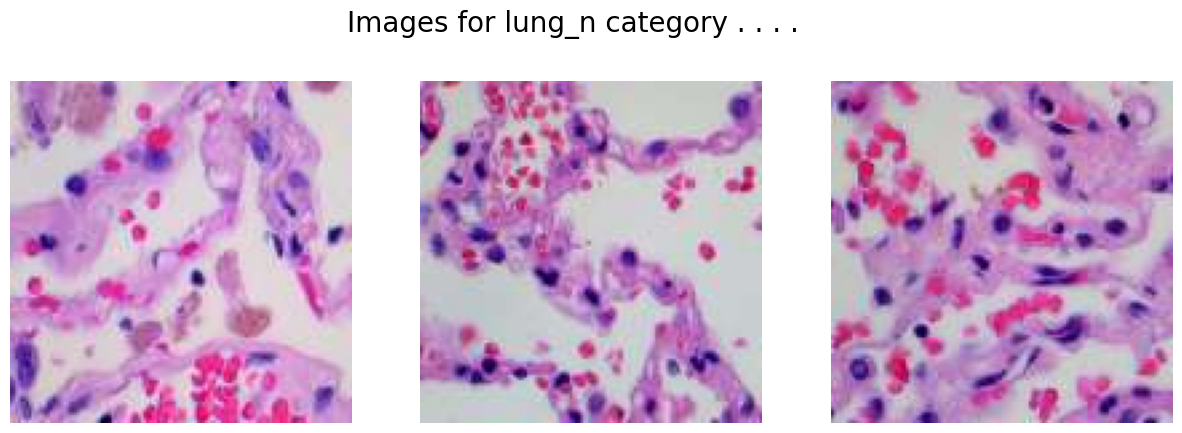

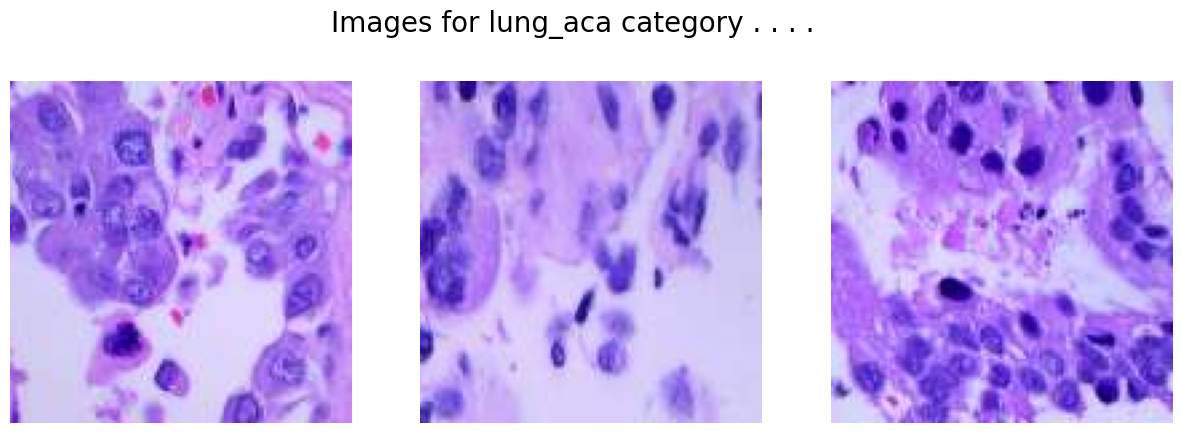

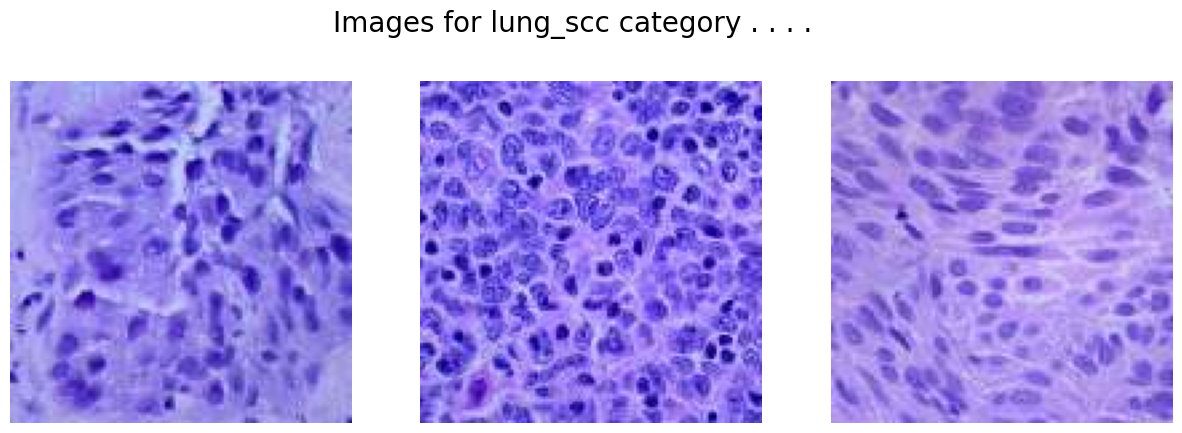

In [ ]:
path = 'lung_subset_small'
classes = ['lung_n', 'lung_aca', 'lung_scc']
for cat in classes:
    image_dir = f'{path}/{cat}'
    images = os.listdir(image_dir)
    fig, ax = plt.subplots(1, 3, figsize=(15, 5))
    fig.suptitle(f'Images for {cat} category . . . .', fontsize=20)
    for i in range(3):
        k = np.random.randint(0, len(images))
        img = np.array(Image.open(f'{path}/{cat}/{images[k]}'))
        ax[i].imshow(img)
        ax[i].axis('off')
    plt.show()

In [15]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

In [ ]:
IMG_SIZE = 128      
BATCH_SIZE = 16    
EPOCHS = 10

datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2)

train_data = datagen.flow_from_directory(
    path,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='training')

val_data = datagen.flow_from_directory(
    path,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='validation')

Found 1920 images belonging to 3 classes.


Found 480 images belonging to 3 classes.


In [17]:
model = keras.models.Sequential([
    layers.Conv2D(32, (5, 5), activation='relu', padding='same', input_shape=(IMG_SIZE, IMG_SIZE, 3)),
    layers.MaxPooling2D(2, 2),

    layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D(2, 2),

    layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D(2, 2),

    layers.Flatten(),
    layers.Dense(256, activation='relu'),
    layers.BatchNormalization(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),
    layers.BatchNormalization(),
    layers.Dense(3, activation='softmax')
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │         2,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     8,388,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,518,467 (32.50 MB)

 Trainable params: 8,517,699 (32.49 MB)

 Non-trainable params: 768 (3.00 KB)

In [18]:
from keras.callbacks import EarlyStopping, ReduceLROnPlateau

class myCallback(tf.keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs=None):
        if logs.get('val_accuracy') > 0.90:
            print("Stopping early")
            self.model.stop_training = True

es = EarlyStopping(patience=3, monitor='val_accuracy', restore_best_weights=True)

lr = ReduceLROnPlateau(monitor='val_loss', patience=2, factor=0.5)

model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [22]:
history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=EPOCHS,
    callbacks=[lr, myCallback()]
)

Epoch 1/10
120/120 ━━━━━━━━━━━━━━━━━━━━ 29s 244ms/step - accuracy: 0.8479 - loss: 0.3904 - val_accuracy: 0.6729 - val_loss: 0.8108 - learning_rate: 5.0000e-04
Epoch 2/10
120/120 ━━━━━━━━━━━━━━━━━━━━ 20s 165ms/step - accuracy: 0.8776 - loss: 0.3400 - val_accuracy: 0.7104 - val_loss: 0.8239 - learning_rate: 5.0000e-04
Epoch 3/10
120/120 ━━━━━━━━━━━━━━━━━━━━ 19s 160ms/step - accuracy: 0.8750 - loss: 0.3064 - val_accuracy: 0.7583 - val_loss: 0.6676 - learning_rate: 5.0000e-04
Epoch 4/10
120/120 ━━━━━━━━━━━━━━━━━━━━ 20s 163ms/step - accuracy: 0.8969 - loss: 0.2630 - val_accuracy: 0.3500 - val_loss: 6.9769 - learning_rate: 5.0000e-04
Epoch 5/10
120/120 ━━━━━━━━━━━━━━━━━━━━ 20s 165ms/step - accuracy: 0.8964 - loss: 0.2580 - val_accuracy: 0.6500 - val_loss: 1.8723 - learning_rate: 5.0000e-04
Epoch 6/10
120/120 ━━━━━━━━━━━━━━━━━━━━ 19s 160ms/step - accuracy: 0.9349 - loss: 0.1900 - val_accuracy: 0.6021 - val_loss: 1.8405 - learning_rate: 2.5000e-04
Epoch 7/10
120/120 ━━━━━━━━━━━━━━━━━━━━ 19s 15

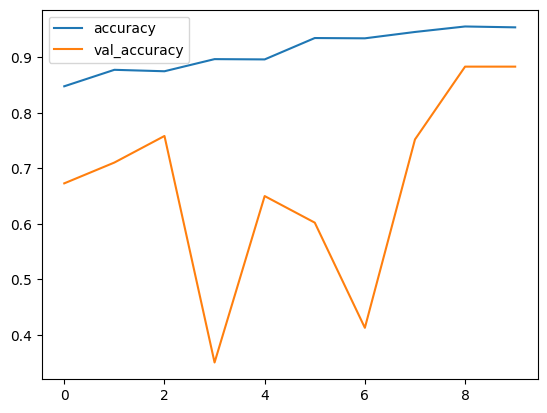

In [23]:
history_df = pd.DataFrame(history.history)
history_df.loc[:, ['accuracy', 'val_accuracy']].plot()
plt.show()

In [24]:
Y_pred = model.predict(val_data)
Y_pred_labels = np.argmax(Y_pred, axis=1)
Y_true = val_data.classes
from sklearn import metrics

print(metrics.classification_report(
    Y_true,
    Y_pred_labels,
    target_names=classes
))

30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step
              precision    recall  f1-score   support

      lung_n       0.30      0.28      0.29       160
    lung_aca       0.33      0.32      0.33       160
    lung_scc       0.31      0.34      0.32       160

    accuracy                           0.31       480
   macro avg       0.31      0.31      0.31       480
weighted avg       0.31      0.31      0.31       480

